# 27 · Joint financial uncertainty

**Good forecasts for each series can still make a bad joint forecast.** Start with four mechanisms, forecast both targets, then deliberately break the pairing between their future trajectories. The per-series distributions stay identical; joint uncertainty changes.

The model receives observed history only. Generator parameters and hidden-state references belong to the evaluator. These are controlled software demonstrations, not financial performance estimates.

In [1]:
from copy import deepcopy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from timegym import Scenario, Pipeline, GaussianAR1Forecaster, Forecast, TestReport, metrics
from timegym.diagnostics import covariance_dependence_check, evaluate_forecast

BLUE, GRAY, TEAL = '#0000ff', '#808080', '#087e8b'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlesize': 11, 'axes.titlelocation': 'left'})

## Four ways to move together

- **Composed levels:** different trends and cycles, correlated accumulated shocks, shared jumps.
- **Merton log prices:** correlated diffusion and a shared jump clock with correlated jump sizes.
- **CCC-GARCH returns:** each target has its own volatility recursion; standardized innovations are correlated.
- **Hidden-regime returns:** both targets share a hidden state; correlations can differ between states.

Scalar target parameters broadcast. Use vectors for per-target settings and `(regime, target)` arrays for state-dependent settings. In Markov examples, the reference infers a single state posterior from **both** observed series.

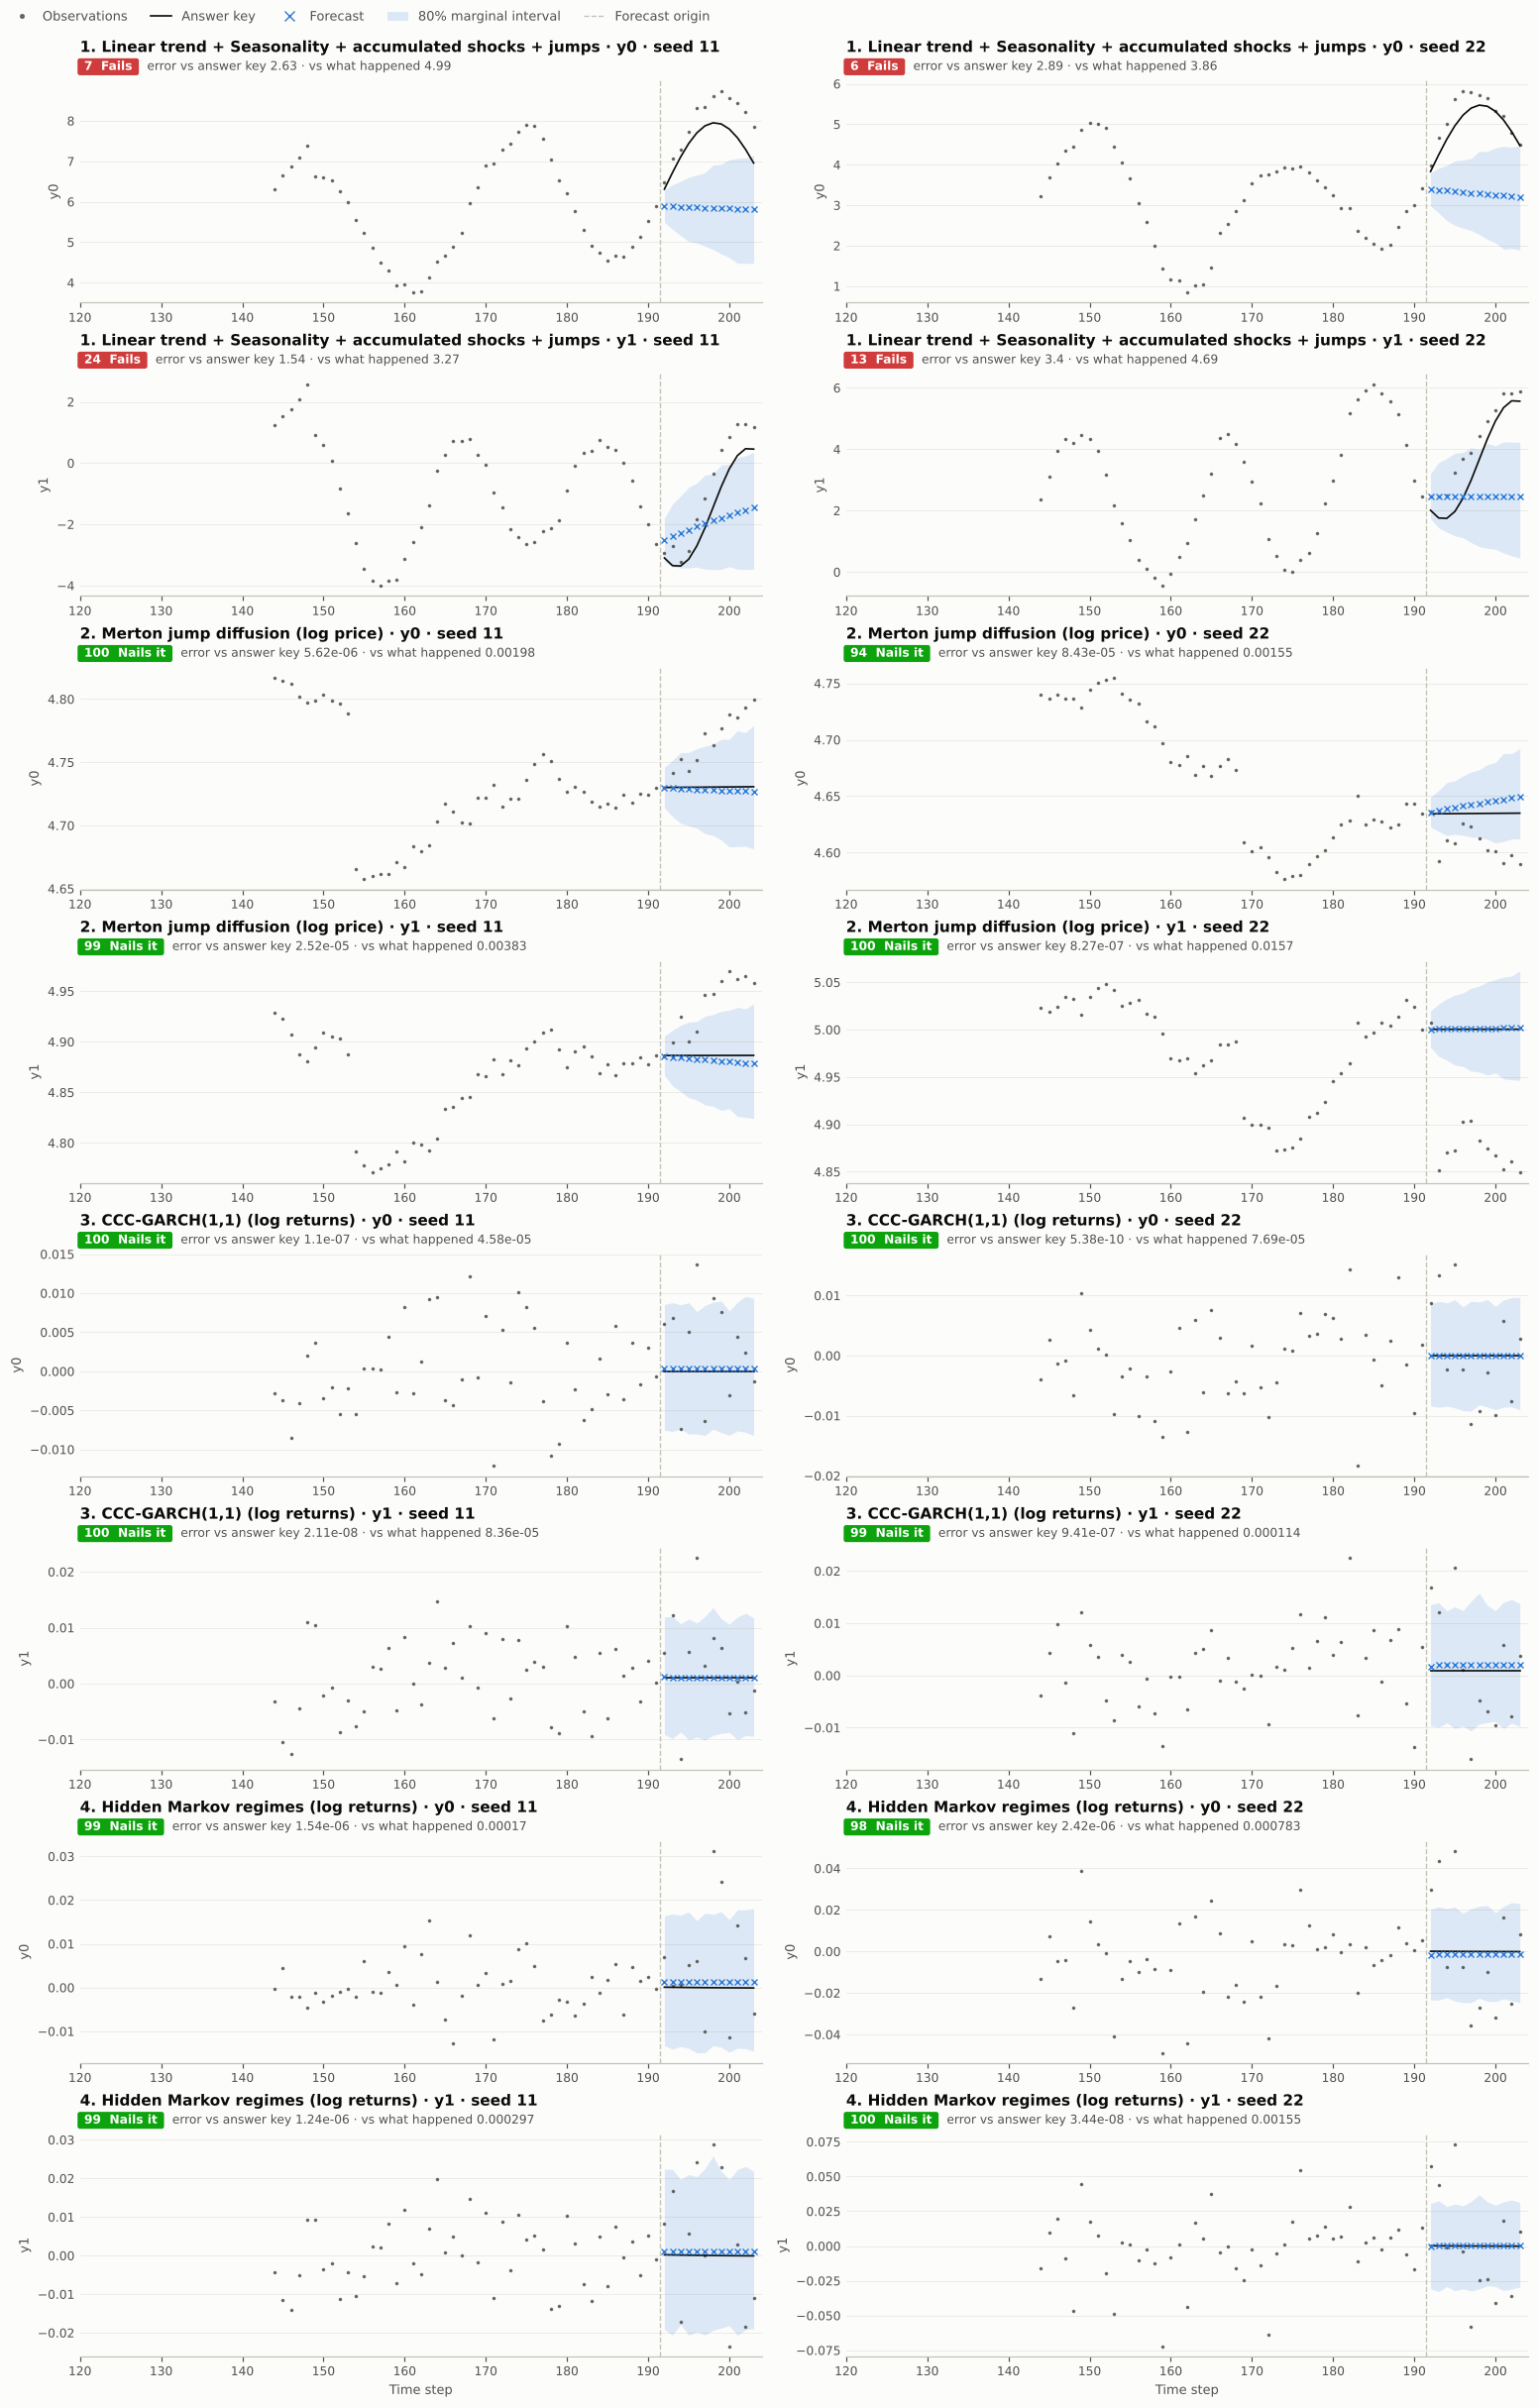

In [2]:
joint_specs = [
    {'kind': 'composite', 'parameters': {'slope': [.02, -.01], 'amplitude': [1.5, 2.],
        'period': [24., 18.], 'sigma': [.15, .25], 'residual': 'random_walk',
        'correlation': .7, 'jump_rate': .035, 'jump_mean': [.1, -.1],
        'jump_sigma': [.4, .6], 'jump_correlation': .8}},
    {'kind': 'merton_jump_diffusion', 'parameters': {'mu': [.04, .07], 'sigma': [.15, .22],
        'correlation': .8, 'jump_rate': 4., 'jump_mean': [-.04, -.08],
        'jump_sigma': [.08, .13], 'jump_correlation': .9, 'output': 'log_price'}},
    {'kind': 'garch', 'parameters': {'mu': [0., .001], 'omega': [3e-6, 8e-6],
        'alpha': [.12, .18], 'beta': [.82, .72], 'correlation': .8, 'output': 'log_return'}},
    {'kind': 'markov_switching', 'parameters': {'regime_mu': [[.04, .08], [-.15, -.2]],
        'regime_sigma': [[.1, .15], [.4, .55]],
        'regime_correlation': [[[1., .3], [.3, 1.]], [[1., .9], [.9, 1.]]],
        'output': 'log_return'}},
]
labels = ['Composed levels', 'Merton log prices', 'CCC-GARCH returns', 'Hidden-regime returns']
scenarios = [Scenario(context_length=192, horizon=12, n_targets=2, **spec) for spec in joint_specs]
fitted = Pipeline(GaussianAR1Forecaster(n_samples=512, seed=71)).run(scenarios, seeds=[11, 22])
fig = fitted.plot_forecasts(show_quantiles=True, figsize=(14, 22))
for ax in fig.axes:
    ax.set_xlim(192-72, 192+12)
plt.show()

## Keep the marginals, break the partners

The blue crosses above come from a fitted Gaussian AR(1) baseline. Its bands are **marginal 80% intervals**, not simultaneous regions, and its simple assumptions need not fit these mechanisms.

Below, use evaluator reference ensembles as controlled fixtures to isolate a distributional bug. Permute **whole trajectories of target 1** across sample identities. Every per-target value and within-target temporal path is preserved, but target 0 is paired with a different target 1. This is more specific than shuffling every horizon independently.

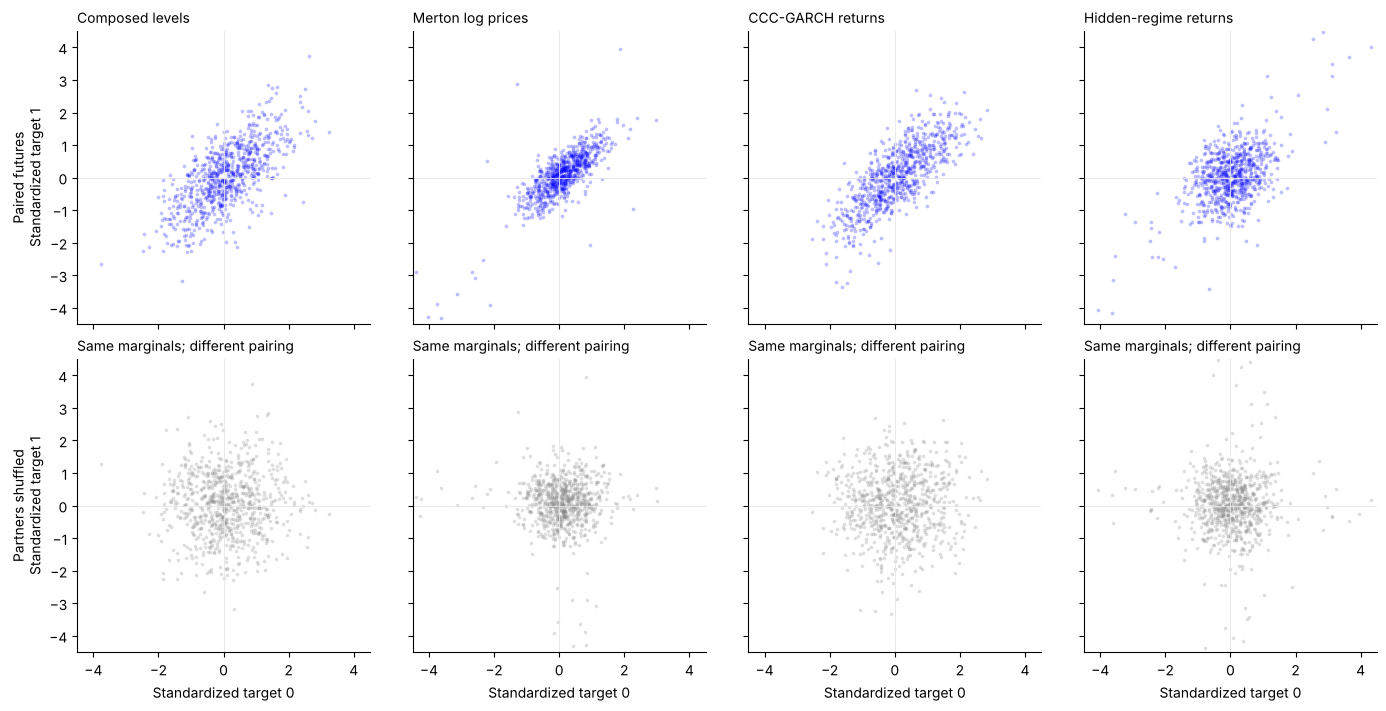

In [3]:
cases = [Scenario(context_length=192, horizon=6, n_targets=2, **spec).generate(seed=11)
         for spec in joint_specs]
clean = [case.reference.forecast(n_samples=768, seed=91) for case in cases]
permutation = np.random.default_rng(18).permutation(768)
broken = []
for forecast in clean:
    altered = deepcopy(forecast)
    altered.samples[:, :, 1] = forecast.samples[permutation, :, 1]
    np.testing.assert_array_equal(np.sort(altered.samples, axis=0), np.sort(forecast.samples, axis=0))
    np.testing.assert_array_equal(altered.samples[:, :, 1], forecast.samples[permutation, :, 1])
    broken.append(altered)

H = 3  # fourth future observation
fig, axes = plt.subplots(2, 4, figsize=(14, 7), layout='constrained', sharex=True, sharey=True)
for col, (label, case, original, altered) in enumerate(zip(labels, cases, clean, broken)):
    for row, (name, forecast, color) in enumerate([('Paired futures', original, BLUE),
                                                  ('Partners shuffled', altered, GRAY)]):
        points = (forecast.samples[:, H]-case.reference.mean[H])/np.sqrt(case.reference.variance[H])
        ax = axes[row, col]
        ax.scatter(points[:, 0], points[:, 1], s=7, color=color, alpha=.25, linewidths=0)
        ax.axhline(0, color='0.9', lw=.6); ax.axvline(0, color='0.9', lw=.6)
        ax.set(xlim=(-4.5, 4.5), ylim=(-4.5, 4.5), aspect='equal')
        ax.set_title(label if row == 0 else 'Same marginals; different pairing', fontsize=10)
        if col == 0: ax.set_ylabel(name+'\nStandardized target 1')
        if row == 1: ax.set_xlabel('Standardized target 0')
plt.show()

## Joint uncertainty changes what an aggregate can do

Focus on Merton log prices. The maps include both cross-series and cross-horizon correlations. Shuffling preserves each target's temporal dependence while disrupting the blocks connecting the targets.

The aggregate below is the equal-weight average of the **standardized forecast errors** at horizon four. It is a diagnostic quantity, not a portfolio-return calculation. Its distribution depends on the pairing even though every marginal interval is unchanged. All draws enter the calculations; the cloud view above is limited to ±4.5 standard deviations.

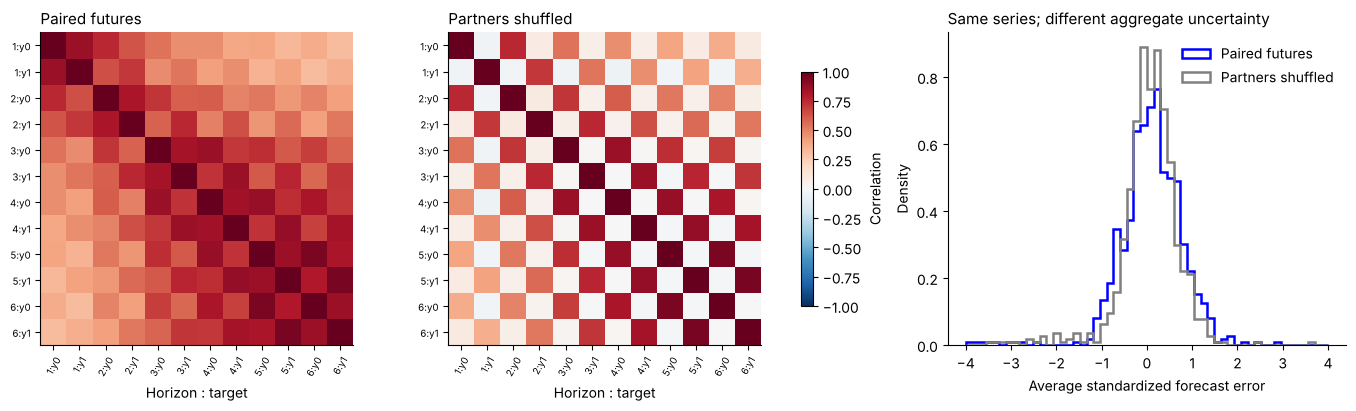

,Aggregate standard deviation
Paired futures,0.906330
Partners shuffled,0.667508


In [4]:
case, original, altered = cases[1], clean[1], broken[1]
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout='constrained')
coordinate_labels = [f'{h+1}:{target}' for h in range(6) for target in case.task.target_names]
for ax, title, forecast in zip(axes[:2], ['Paired futures', 'Partners shuffled'], [original, altered]):
    correlation = np.corrcoef(forecast.samples.reshape(768, -1), rowvar=False)
    im = ax.imshow(correlation, vmin=-1, vmax=1, cmap='RdBu_r')
    ax.set_title(title)
    ax.set_xticks(range(12), coordinate_labels, rotation=60, fontsize=7)
    ax.set_yticks(range(12), coordinate_labels, fontsize=7)
    ax.set_xlabel('Horizon : target')
fig.colorbar(im, ax=list(axes[:2]), shrink=.75, label='Correlation')
aggregate_sd = {}
for name, forecast, color in [('Paired futures', original, BLUE), ('Partners shuffled', altered, GRAY)]:
    errors = (forecast.samples[:, H]-case.reference.mean[H])/np.sqrt(case.reference.variance[H])
    aggregate = errors.mean(axis=1)
    aggregate_sd[name] = aggregate.std(ddof=1)
    axes[2].hist(aggregate, bins=np.linspace(-4, 4, 55), density=True,
                 histtype='step', linewidth=1.8, color=color, label=name)
axes[2].set_title('Same series; different aggregate uncertainty')
axes[2].set_xlabel('Average standardized forecast error'); axes[2].set_ylabel('Density')
axes[2].legend(frameon=False)
plt.show()
display(pd.Series(aggregate_sd, name='Aggregate standard deviation').to_frame())

## Diagnose the injected fault, then verify repair

Marginal CRPS must be unchanged by construction. Joint scores can change, but one observed future does not guarantee a particular score ordering. The covariance diagnostic compares whole-trajectory ensembles with independent null ensembles; a clean ensemble can still be rejected at the stated per-check error rate.

For CCC-GARCH, the analytical mean and marginal variances accompany an explicitly estimated cross-covariance. That numerical matrix is held fixed throughout rank calibration, using a separate random stream from all forecast and calibration ensembles. Exact conditional sampling and exact moments are separate capabilities.

In [5]:
rows = []
for label, case, original, altered in zip(labels, cases, clean, broken):
    observed = case.observed.to_numpy()
    np.testing.assert_allclose(metrics.crps(observed, original.samples), metrics.crps(observed, altered.samples), rtol=0, atol=1e-13)
    for name, forecast in [('Paired', original), ('Shuffled', altered), ('Repaired', deepcopy(original))]:
        check = covariance_dependence_check(case.reference, forecast.samples, seed=741, n_calibration=39)
        rows.append({'Case': label, 'Ensemble': name,
                     'Marginal CRPS': metrics.crps(observed, forecast.samples),
                     'Energy score': metrics.energy_score(observed, forecast.samples),
                     'Variogram score': metrics.variogram_score(observed, forecast.samples),
                     'Covariance check': check.status, 'p-value': check.evidence.get('p_value')})
summary = pd.DataFrame(rows)
display(summary.set_index(['Case', 'Ensemble']).round(5))
for label in labels:
    paired = summary[(summary.Case == label) & (summary.Ensemble == 'Paired')].iloc[0]
    repaired = summary[(summary.Case == label) & (summary.Ensemble == 'Repaired')].iloc[0]
    assert paired['Covariance check'] == repaired['Covariance check']
    assert paired['p-value'] == repaired['p-value']
display(pd.DataFrame([{'Case': label, **getattr(case.reference, 'capabilities', {})}
                      for label, case in zip(labels, cases)]).set_index('Case'))

Marginal CRPS  Energy score  Variogram score  \
Case                  Ensemble                                                 
Composed levels       Paired          0.27173       1.12776          0.02353   
                      Shuffled        0.27173       1.15410          0.02351   
                      Repaired        0.27173       1.12776          0.02353   
Merton log prices     Paired          0.01260       0.05519          0.00175   
                      Shuffled        0.01260       0.05739          0.00175   
                      Repaired        0.01260       0.05519          0.00175   
CCC-GARCH returns     Paired          0.00621       0.02616          0.00227   
                      Shuffled        0.00621       0.02623          0.00225   
                      Repaired        0.00621       0.02616          0.00227   
Hidden-regime returns Paired          0.00613       0.02725          0.00191   
                      Shuffled        0.00613       0.02717          0.00189   
                      Repaired        0.00613       0.02725          0.00191   

                               Covariance check  p-value  
Case                  Ensemble                            
Composed levels       Paired               PASS    0.275  
                      Shuffled             FAIL    0.025  
                      Repaired             PASS    0.275  
Merton log prices     Paired               PASS    0.575  
                      Shuffled             FAIL    0.025  
                      Repaired             PASS    0.575  
CCC-GARCH returns     Paired               PASS    0.700  
                      Shuffled             FAIL    0.025  
                      Repaired             PASS    0.700  
Hidden-regime returns Paired               PASS    0.825  
                      Shuffled             FAIL    0.025  
                      Repaired             PASS    0.825

,moments_kind,sampler_kind,quantiles_kind,quantile_samples,quantile_seed,quantile_method,mean_kind,covariance_kind,moment_samples,moment_seed
Case,,,,,,,,,,
Composed levels,analytic,exact_conditional,monte_carlo,8192,0,linear,NaN,NaN,NaN,NaN
Merton log prices,analytic,exact_conditional,monte_carlo,8192,0,linear,NaN,NaN,NaN,NaN
CCC-GARCH returns,analytic_mean_monte_carlo_covariance,exact_conditional,monte_carlo,8192,0,linear,analytic,monte_carlo,16384.0,0.0
Hidden-regime returns,analytic,exact_conditional,monte_carlo,8192,0,linear,NaN,NaN,NaN,NaN


## Add jumps to the hidden regimes—and keep the approximation visible

Now let jump arrivals and sizes depend on the shared regime. The reference filters a truncated multivariate Poisson mixture. Its omitted emission probability is recorded; it is **not** a posterior-error bound. Joint samples and descriptive scores remain available, while the exact covariance diagnostic returns `UNSUPPORTED`.

Multivariate regime filtering currently requires positive diffusion scales and positive-definite within-regime correlation matrices. Singular Gaussian laws remain supported in the other joint families.

In [6]:
jump_settings = {**joint_specs[3]['parameters'],
                 'regime_jump_rate': [2., 12.],
                 'regime_jump_mean': [[-.02, -.03], [-.08, -.12]],
                 'regime_jump_sigma': [[.02, .04], [.08, .12]],
                 'jump_correlation': .8}
jump_case = Scenario('markov_switching', 192, 6, jump_settings, n_targets=2).generate(seed=11)
jump_forecast = jump_case.reference.forecast(256, seed=91)
check = covariance_dependence_check(jump_case.reference, jump_forecast.samples)
assert check.status == 'UNSUPPORTED'
display(pd.Series(jump_case.reference.conditioning))
print(check.status + ': ' + check.message)

observed_through                                                                191
known_generator_parameters                                                     True
future_observations_used                                                      False
output_units                                                             log_return
state_posterior                                                [0.994755, 0.005245]
state_inference                                 forward_filter_all_observed_targets
hidden_states_exposed_to_model                                                False
dependence                        shared_hidden_chain_correlated_diffusion_and_s...
emission_poisson_tail_bound                                                     0.0
filter_note                       truncated_joint_emission_mixture; tail_bound_i...
moments_conditioning                                 numerically_filtered_posterior
moments_kind                                                               a

UNSUPPORTED: An approximate reference simulator cannot calibrate an exact conditional-law diagnostic.


## Replay the fitted model, reserve the next experiments

Replay reconstructs the generator, dependence assumptions, fitted model, and numerical-reference settings. The examples above establish controlled software behaviour. Reserve other seeds, dependence matrices, parameter regions, and combinations before comparing performance on untouched real data.

Try negative shock correlation, zero jump intensity, or equal regimes one at a time. Setting ordinary shock correlation to zero does **not** remove dependence induced by shared jump counts or a shared hidden state. Shared versus idiosyncratic shocks, CCC versus dynamically changing conditional correlations, and changing transition laws are distinct model choices.

In [7]:
loaded = TestReport.from_json(fitted.report.to_json())
replay = loaded.replay_case(4)  # CCC-GARCH, first seed
assert replay.metadata['replay']['manifest_match']
assert replay.metadata['replay']['metrics_match']
assert replay.metadata['replay']['diagnostics_match']
replay.metadata['replay']

{'case_index': 4,
 'metrics_match': True,
 'diagnostics_match': True,
 'traceback_match': True,
 'manifest_match': True,
 'source_matches': True,
 'dependencies_match': True,
 'python_matches': True,
 'reproduced': True,
 'same_environment': True}